# 量子保密通信 · BB84、窃听误码与纠错教学块

QuantumBridge / 量子安全 / 中文可执行案例

**执行状态：仅本地运行；未提交夸父真机；新增云任务 0。**

面向了解 Python 的读者：完成建模、检查中间结果、运行原生电路或明确标记的经典密码步骤，并与独立基线核对。

**范围边界：** 没有真实光链路、设备噪声校准、身份认证信道、有限密钥证明、完整纠错或隐私放大；不构成可部署 QKD 网络。公开种子与转录不能用作秘密密钥。

## 1. 原理与计算对象

Alice 随机选择比特和 Z/X 编码基，Bob 随机选测量基，公开比较基后保留一致的记录。本例固定随机种子，全部数据公开，仅用于教学。
无噪且无窃听时，筛选后的 QBER 为 0。Eve 随机选基截获并重发，有一半概率选错基，错基分支中 Bob 又有一半概率出错，所以理想截获重发 QBER 为 1/4。每个比特由原生单比特电路制备与采样，不用事先写死 25% 作为实验结果。

另演示 Hamming(7,4) 的单比特纠错：四个数据位扩成七码，异或校验给出错误位置。它不能保证纠正双错，不是完整 QKD 纠错与隐私放大协议。11% 仅作为本例的示意终止阈值，不能当成任意设备、有限密钥长度下的安全证书。

## 2. 实现步骤

1. 运行无 Eve 与截获重发两个 1024 光子模拟场景。
2. 公开展示前 24 条基选择、接收位与筛选标志；统计筛选数与误码。
3. 比较实际 QBER 和 0/0.25 理论值，超过示意阈值中止。
4. 演示一个教学码字的单错、综合征和恢复数据。
5. 输出三个制备/测量基电路与采样结果，明确不产生生产密钥。

## 3. 环境与可复现参数

依赖本仓库、NumPy、Matplotlib、Jupyter；安全案例还使用已安装的 OpenSSL / cryptography。模型和电路不调用 Qiskit 或 PennyLane。Notebook 保留真实执行输出，Python 解释器版本会在下方打印。

In [1]:
import os, sys, json
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
root = next((p for p in [Path(os.environ.get("QB_REPO_ROOT", ".")).resolve(), *Path.cwd().resolve().parents] if (p/"quantumbridge").is_dir() and (p/"scripts").is_dir()), None)
if root is None:
    raise RuntimeError("Run from the QuantumBridge checkout or set QB_REPO_ROOT.")
sys.path.insert(0, str(root)); sys.path.insert(0, str(root/"scripts"))
from IPython.display import display, HTML
from application_notebook_support import STYLE, show_json, intermediate_tables, plot_intermediate, show_measurements
from quantumbridge.applications.common import run_local_case
display(HTML(STYLE))
SHOTS, SEED = 1024, 20261023
print("Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit:", SHOTS)

print(sys.version)
import copy
import hashlib
import hmac
import json
import os
from pathlib import Path
import shutil
import subprocess
import tempfile
import numpy as np
from quantumbridge.core import Circuit
from quantumbridge.devices import StatevectorDevice
from quantumbridge.finance.kernels import labels
from quantumbridge.applications.common import ApplicationCase

Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit: 1024
3.12.6 (v3.12.6:a4a2d2b0d85, Sep  6 2024, 16:08:03) [Clang 13.0.0 (clang-1300.0.29.30)]


## 4. 完整应用建模代码

以下是本案例实际执行的应用函数，不是伪代码。底层电路、映射、演化与采样复用仓库原生接口；优化类的共享辅助函数也位于 `quantumbridge/applications/common.py`。

In [2]:
def bb84_circuit(bit, basis, measurement_basis):
    circuit = Circuit(1, name="bb84-prepare-and-measure")
    if bit:
        circuit.x(0)
    if basis:
        circuit.h(0)
    if measurement_basis:
        circuit.h(0)
    return circuit


def bb84_transcript(*, eve=False, photons=1024, seed=20261023):
    if type(photons) is not int or not 8 <= photons <= 4096:
        raise ValueError("Use eight to 4096 simulated photons.")
    rng, device = np.random.default_rng(seed), StatevectorDevice()
    rows = []
    for index in range(photons):
        bit, basis, bob_basis, eve_basis = map(int, rng.integers(0, 2, size=4))
        send_bit, send_basis = bit, basis
        if eve:
            sample = device.sample(
                bb84_circuit(bit, basis, eve_basis), shots=1, seed=seed + 2 * index
            )[0]
            send_bit, send_basis = int(sample), eve_basis
        received = int(
            device.sample(
                bb84_circuit(send_bit, send_basis, bob_basis),
                shots=1,
                seed=seed + 2 * index + 1,
            )[0]
        )
        rows.append(
            {
                "index": index,
                "alice_bit": bit,
                "alice_basis": basis,
                "bob_basis": bob_basis,
                "bob_bit": received,
                "sifted": basis == bob_basis,
            }
        )
    sifted = [row for row in rows if row["sifted"]]
    errors = sum(row["alice_bit"] != row["bob_bit"] for row in sifted)
    qber = errors / len(sifted)
    return {
        "photons": photons,
        "sifted_count": len(sifted),
        "sifted_errors": errors,
        "qber": qber,
        "qber_standard_error": float(
            np.sqrt(qber * (1 - qber) / max(1, len(sifted) - 1))
        ),
        "eve": eve,
        "public_teaching_transcript_first24": rows[:24],
    }


def hamming_encode(data):
    if len(data) != 4 or any(bit not in (0, 1) for bit in data):
        raise ValueError("Four binary data symbols are required.")
    word = [0] * 8
    for index, bit in zip((3, 5, 6, 7), data):
        word[index] = int(bit)
    for parity in (1, 2, 4):
        word[parity] = sum(word[i] for i in range(1, 8) if i & parity) % 2
    return word[1:]


def hamming_correct(word):
    if len(word) != 7 or any(bit not in (0, 1) for bit in word):
        raise ValueError("Seven binary code symbols are required.")
    corrected = list(word)
    syndrome = 0
    for index, bit in enumerate(word, 1):
        if bit:
            syndrome ^= index
    if syndrome:
        corrected[syndrome - 1] ^= 1
    return [corrected[i - 1] for i in (3, 5, 6, 7)], syndrome


def qkd_case():
    clean, intercepted = bb84_transcript(), bb84_transcript(eve=True)
    encoded = hamming_encode([1, 0, 1, 1])
    changed = list(encoded)
    changed[4] ^= 1
    recovered, syndrome = hamming_correct(changed)
    return ApplicationCase(
        "qkd",
        "security",
        "BB84 sifting and intercept-resend experiment",
        {
            "photons_per_scenario": 1024,
            "seed": 20261023,
            "channel": "ideal local single-qubit simulation",
            "eve_model": "random-basis intercept-resend",
            "illustrative_abort_qber": 0.11,
        },
        {
            "scenarios": [
                {
                    k: v
                    for k, v in row.items()
                    if k != "public_teaching_transcript_first24"
                }
                for row in (clean, intercepted)
            ],
            "clean_transcript_first24": clean["public_teaching_transcript_first24"],
            "eve_transcript_first24": intercepted["public_teaching_transcript_first24"],
            "single_error_correction_example": {
                "data": [1, 0, 1, 1],
                "encoded": encoded,
                "corrupted": changed,
                "syndrome": syndrome,
                "decoded": recovered,
                "limit": "Hamming(7,4) single-error teaching block; not a QKD reconciliation stack; no double-error guarantee",
            },
            "chart_rows": [
                {"label": "No Eve", "value": clean["qber"]},
                {"label": "Intercept-resend", "value": intercepted["qber"]},
            ],
            "chart_units": "Sifted QBER",
            "chart_title": "Seeded local BB84 protocol experiment",
        },
        {"ideal_clean_qber": 0.0, "ideal_intercept_resend_qber": 0.25},
        {
            "z_basis_bit1": bb84_circuit(1, 0, 0),
            "x_basis_bit1": bb84_circuit(1, 1, 1),
            "mismatched_bases": bb84_circuit(1, 0, 1),
        },
        {
            name: [0.0, 1.0]
            for name in ("z_basis_bit1", "x_basis_bit1", "mismatched_bases")
        },
        {
            "clean_qber": clean["qber"],
            "eve_qber": intercepted["qber"],
            "eve_scenario_aborted": intercepted["qber"] > 0.11,
            "production_key_emitted": False,
            "authentication_and_finite_key_proof": "not implemented; all bits are public seeded teaching data",
        },
    )


In [3]:
case = qkd_case()
show_json(case.inputs)

## 5. 中间结果与效果

下方完整列出模型候选、优化轨迹或物理中间量。图中的 exact / classical 是经典计算基线，不冒充量子实验。图表使用英文坐标避免本机中文字体缺失，解释与表格保留中文。

photons,sifted_count,sifted_errors,qber,qber_standard_error,eve
1024,507,0,0,0,False
1024,507,131,0.25838264,0.019460158,True


index,alice_bit,alice_basis,bob_basis,bob_bit,sifted
0,1,0,0,1,True
1,1,1,1,1,True
2,1,1,1,1,True
3,0,0,1,0,False
4,0,1,1,0,True
5,1,1,1,1,True
6,0,1,1,0,True
7,1,1,0,1,False
8,0,1,0,0,False
9,0,0,1,0,False


index,alice_bit,alice_basis,bob_basis,bob_bit,sifted
0,1,0,0,1,True
1,1,1,1,1,True
2,1,1,1,0,True
3,0,0,1,0,False
4,0,1,1,1,True
5,1,1,1,1,True
6,0,1,1,0,True
7,1,1,0,1,False
8,0,1,0,1,False
9,0,0,1,0,False


label,value
No Eve,0
Intercept-resend,0.25838264


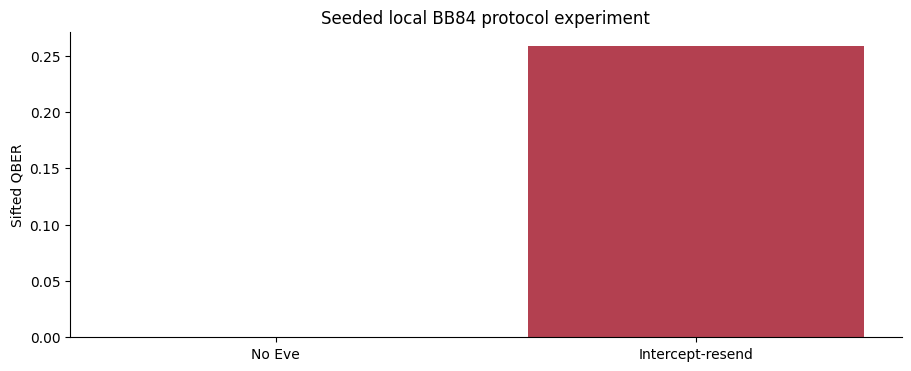

In [4]:
intermediate_tables(case)
plot_intermediate(case)

## 6. 实际运行与最终效果

模拟器使用固定种子逐次采样，counts 总数必须等于 shots。估计标准误由实际样本方差计算；近似 95% 区间可写作 estimate ± 1.96 × SE，但小样本及零计数需另用适当区间。本例不把这些区间当成硬件精度验收。

experiment,qubits,gates,shots,seed
z_basis_bit1,1,1,1024,20261023
x_basis_bit1,1,3,1024,20261024
mismatched_bases,1,2,1024,20261025


observable,estimate,standard_error,ideal_reference
z_basis_bit1,1,0,1
x_basis_bit1,1,0,1
mismatched_bases,0.48339844,0.015624016,0.5


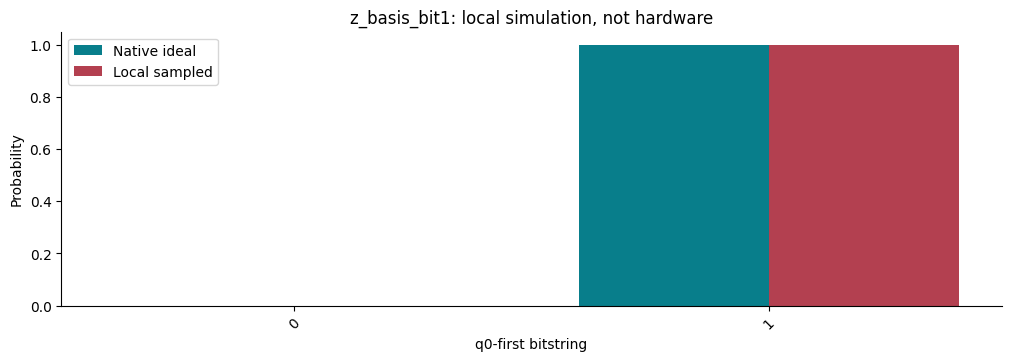

experiment,counts
z_basis_bit1,"{""1"": 1024}"
x_basis_bit1,"{""1"": 1024}"
mismatched_bases,"{""0"": 529, ""1"": 495}"


In [5]:
evidence = run_local_case(case, shots=SHOTS, seed=SEED)
show_measurements(case, evidence)

## 7. 可检查的电路输出

导出全部业务电路的 OpenQASM 2，位串采用 q0-first。可导出不等于已通过夸父设备门集、耦合图、深度和精度验收；本批不会访问凭据、提交任务或消耗金融额度。纯经典案例没有伪造量子电路。

In [6]:
for name, result in evidence['experiments'].items():
    print('\n---', name, '---\n'+result['openqasm2'])
if not evidence['experiments']:
    print('Classical cryptography / security workflow: no quantum circuit.')


--- z_basis_bit1 ---
OPENQASM 2.0;
include "qelib1.inc";
qreg q[1];
creg c[1];
x q[0];
measure q[0] -> c[0];


--- x_basis_bit1 ---
OPENQASM 2.0;
include "qelib1.inc";
qreg q[1];
creg c[1];
x q[0];
h q[0];
h q[0];
measure q[0] -> c[0];


--- mismatched_bases ---
OPENQASM 2.0;
include "qelib1.inc";
qreg q[1];
creg c[1];
x q[0];
h q[0];
measure q[0] -> c[0];



## 8. 结果解释、复做与非目标

查看 scenarios 的筛选数、误码数和 qber，再看 eve_scenario_aborted。三个独立测量示例只解释基选择；协议统计来自前面的逐光子模拟，二者不混称同一批测量。

没有真实光链路、设备噪声校准、身份认证信道、有限密钥证明、完整纠错或隐私放大；不构成可部署 QKD 网络。公开种子与转录不能用作秘密密钥。

练习：对已有电路将 shots 改为 2048，比较估计与标准误；如果是纯经典密码案例，比较密文/公钥大小和篡改检测结果。安全案例的私钥只在临时目录或内存中存在，不输出密钥。重新执行此 Notebook 仍然只运行本地代码。

In [7]:
repeat = run_local_case(case, shots=2048, seed=SEED+100)
show_json({'execution_mode':repeat['execution_mode'], 'estimates':repeat['estimates'], 'new_cloud_tasks':repeat['new_cloud_tasks']})
assert all(sum(row['counts'].values()) == 2048 for row in repeat['experiments'].values())
assert repeat['new_cloud_tasks'] == 0
assert repeat['hardware_access'] is False

In [8]:
artifact = {'inputs':case.inputs, 'intermediate':case.intermediate, 'reference':case.reference, 'evidence':evidence}
path = root/'output/jupyter-notebook/security/02_qkd_evidence.json'
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(artifact, ensure_ascii=False, indent=2), encoding='utf-8')
print('Evidence:', path.name)

Evidence: 02_qkd_evidence.json


## 9. 参考与责任边界

独立编写应用代码，未复制上游 SDK 实现或第三方教程代码；下列资料用于数学与接口背景。

- [IBM BB84 与量子密钥分发教学](https://quantum.cloud.ibm.com/learning/en/modules/computer-science/quantum-key-distribution)

本案例不是生产支持证书，也不代表 Qiskit / PennyLane 全量替代已经完成。